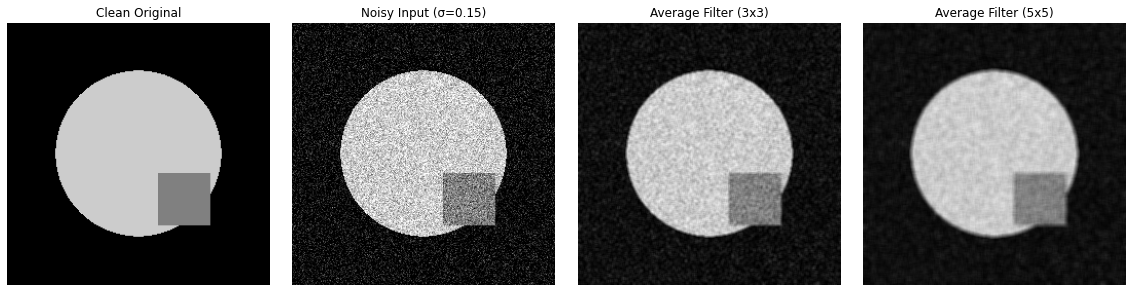

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Generate a clean grayscale test image (256x256) in [0, 1]
N = 256
x = np.linspace(-1, 1, N)
X, Y = np.meshgrid(x, x)

clean_img = np.zeros((N, N), dtype=np.float32)
clean_img[(X**2 + Y**2) < 0.4] = 0.8
clean_img[(np.abs(X - 0.35) < 0.2) & (np.abs(Y - 0.35) < 0.2)] = 0.5

# 2. Add Gaussian noise
rng = np.random.default_rng(seed=42)
noisy_img = np.clip(clean_img + rng.normal(0.0, 0.15, clean_img.shape), 0.0, 1.0).astype(np.float32)

# 3. Implement KxK Average Filter using NumPy only
def average_filter_numpy(image: np.ndarray, ksize: int = 5) -> np.ndarray:
    pad = ksize // 2
    padded = np.pad(image, pad_width=pad, mode="reflect")
    
    # Extract sliding windows of shape (H, W, ksize, ksize)
    windows = np.lib.stride_tricks.sliding_window_view(padded, (ksize, ksize))
    
    # Compute mean over the last two (kernel) axes
    return np.mean(windows, axis=(-2, -1))

# Apply 3x3 and 5x5 average filters
denoised_3x3 = average_filter_numpy(noisy_img, ksize=3)
denoised_5x5 = average_filter_numpy(noisy_img, ksize=5)

# 4. Visualize Results
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
outputs = [
    ("Clean Original", clean_img),
    ("Noisy Input (σ=0.15)", noisy_img),
    ("Average Filter (3x3)", denoised_3x3),
    ("Average Filter (5x5)", denoised_5x5),
]

for ax, (title, im) in zip(axes, outputs):
    ax.imshow(im, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()